# Trajecotry inference for hematopoiesis in mouse

### Aim:
Learn trajectory inference: reconstruct how mouse blood progenitor cells develop into different blood cell types.

### Data:
- Paul et al. 2015: ~2,700 myeloid progenitor cells from mouse bone marrow
- Mouse data, gene names are written like Gata1 not GATA1
- One snapshot with no time labels => order of cells has to be inferred

### Workflow:
1. Preprocess: normalise, select highly variable genes, log-transform and sclae
2. PCA -> neighbourhood graph _. force-directed layout
3. Denoise the graph with a diffusion map
4. Cluster and annoate clusters with marker genes
5. PAGA: draw a simplified graph of how clusters connected and redraw the cell layout from it 
6. Choose a root cell in the stem cluster and compute pseudotime
7. Plot marker genes along three paths (erythrocytes, neutrophils, monocytes)

### Expected output:
A PAGA graph of stem/progenitor cells branching into blood lineages, heatmaps of marker genes changing along pseudotime for each path 

This notebook shows how cells move between states by ordering cells along a continuous process. In tumours, this could follow CD8 T cells from TCF7+ progenitor-like states to exhausted states. This matters because TCF7+ CD8 T cells are linked to anti-PD-1 response (Sade-Feldman et al., 2018).

In [1]:
from __future__ import annotations
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

In [2]:
sc.settings.verbosity = 3  # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_versions()
results_file = "./write/paul15.h5ad"
# low dpi (dots per inch) yields small inline figures
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(3, 3), facecolor="white")

/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_33742/907791383.py:2: FutureWarning: The function print_versions is deprecated and will be removed in the future. Use :func:`print_header` instead.
  sc.logging.print_versions()
/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_33742/907791383.py:5: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(3, 3), facecolor="white")


In [3]:
adata = sc.datasets.paul15()
adata

AnnData object with n_obs × n_vars = 2730 × 3451
    obs: 'paul15_clusters'
    uns: 'iroot'
    layers: None (.X)

In [4]:
# setting higher resolution for consistency across different platforms
adata.X = adata.X.astype("float64")

### Preprocessing

In [5]:
sc.pp.recipe_zheng17(adata)

# this function include preprocessing steps:
    # remove genes with no counts
    # normarlise each cell's total counts
    # keep the 1,000 most variable genes
    # noramlise again
    # log-transform the data
    # scale each gene

running recipe zheng17
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
normalizing counts per cell


/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/scanpy/preprocessing/_recipes.py:185: FutureWarning: The function filter_genes_dispersion is deprecated and will be removed in the future:
    Use :func:`~scanpy.pp.highly_variable_genes` instead.
    The new function is equivalent to the present function, except that

    * the new function always expects logarithmized data
    * `subset=False` in the new function, it suffices to
        merely annotate the genes, tools like `pp.pca` will
        detect the annotation
    * you can now call: `sc.pl.highly_variable_genes(adata)`
    * `copy` is replaced by `inplace`
  filter_result = filter_genes_dispersion(


    finished (0:00:00)
    finished (0:00:00)


In [6]:
sc.tl.pca(adata, svd_solver="arpack") 
# arpack is a fast and memory-efficient algorithm for computing the singular value decomposition (SVD) of a matrix. 
# It is particularly useful for large datasets where the number of features (genes) is much larger than the number of samples (cells).

computing PCA
    with n_comps=50
    finished (0:00:00)


In [7]:
sc.pp.neighbors(adata, n_neighbors=4, n_pcs=20)
# n_neighbour is 4, smaller than default 15, because the dataset is small and we want to capture the local structure of the data.
sc.tl.draw_graph(adata)

computing neighbors
    using 'X_pca' with n_pcs = 20


/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:05)
drawing single-cell graph using layout 'fa'
    finished: added
    'X_draw_graph_fa', graph_drawing coordinates (adata.obsm) (0:00:15)


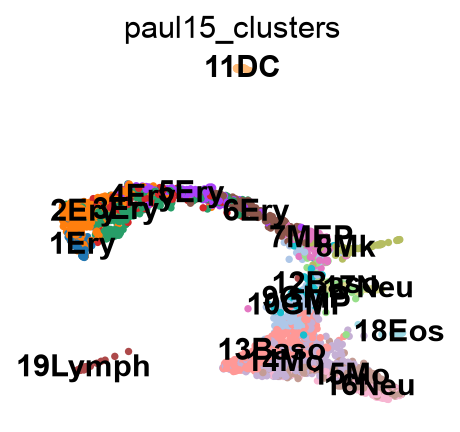

In [8]:
sc.pl.draw_graph(adata, color="paul15_clusters", legend_loc="on data")

In [ ]:
# denoising with a diffusion map 
# diffusion map rearrange the cells by their similarity in gene expression space
# which can help to reveal the underlying structure of the data and reduce noise.
# eigenvalues represent directions produced by diffusion map, 
# between 0 and 1 shows how important that direciton is in explaining the variance in the data.
# eigenvalue close to 1 , big and slow pattern -> main developmental paths
# eigenvalues close to 0, small and fast pattern -> noise
sc.tl.diffmap(adata)
sc.pp.neighbors(adata, n_neighbors=10, use_rep="X_diffmap")

computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         1.         0.9989278  0.99671    0.99430376 0.98939794
     0.9883687  0.98731077 0.98398703 0.983007   0.9790806  0.9762548
     0.9744365  0.9729161  0.9652972 ]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)


drawing single-cell graph using layout 'fa'
    finished: added
    'X_draw_graph_fa', graph_drawing coordinates (adata.obsm) (0:00:13)


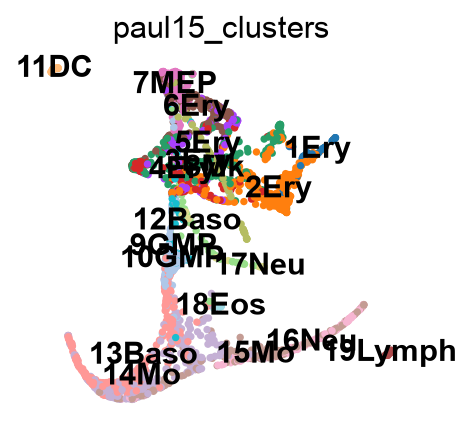

In [11]:
sc.tl.draw_graph(adata)
sc.pl.draw_graph(adata, color="paul15_clusters", legend_loc="on data")

## Clustering and PAGA (Partition-based graph abstraction)

PAGA count links between the clusters from already built neighbour graph and comapre with chance by working out how many links potentially by chance based on cluster size, and give each pair a score from 0 to 1. This allows to see the how each clusters stronlgy connected with another, meaning probably that one stage of cell state leads to the next. 

In [16]:
# this tutorial used older method Louvain to reproudce the paper (Leiden is more recommended with future work)
# could not download louvain package, so using leiden instead
sc.tl.leiden(adata, resolution=0.6, key_added="louvain",
             flavor="igraph", n_iterations=2, directed=False)
# set the resolution to 0.6 to get similar number of clusters as the original paper
adata.obs["louvain"].nunique()   

running Leiden clustering
    finished: found 25 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


25

|cell type | marker|
|---|---|
|HSCs| Procr|
|Erythroids|Gata1, Klf1, Epor, Gypa, Hba-a2, Hba-a1, Spi1|
|Neutrophils|Elane, Cebpe, Ctsg, Mpo, Gfi1|
|Monoctypes|Irf8, Csf1r, Ctsg, Mpo|
|Megakaryocytes|Itga2b (encodes protein CD41), Pbx1, Sdpr, Vwf|
|Basophils|Mcpt8, Prss34|
|B cells|Cd19, Vpreb2, Cd79a|
|Mast cells|Cma1, Gzmb, CD117/C-Kit|
|Mast cells & Basophils|Ms4a2, Fcer1a, Cpa3, CD203c (human)|


In [ ]:
sc.tl.paga(adata, groups="louvain")

running PAGA
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:00)


--> added 'pos', the PAGA positions (adata.uns['paga'])


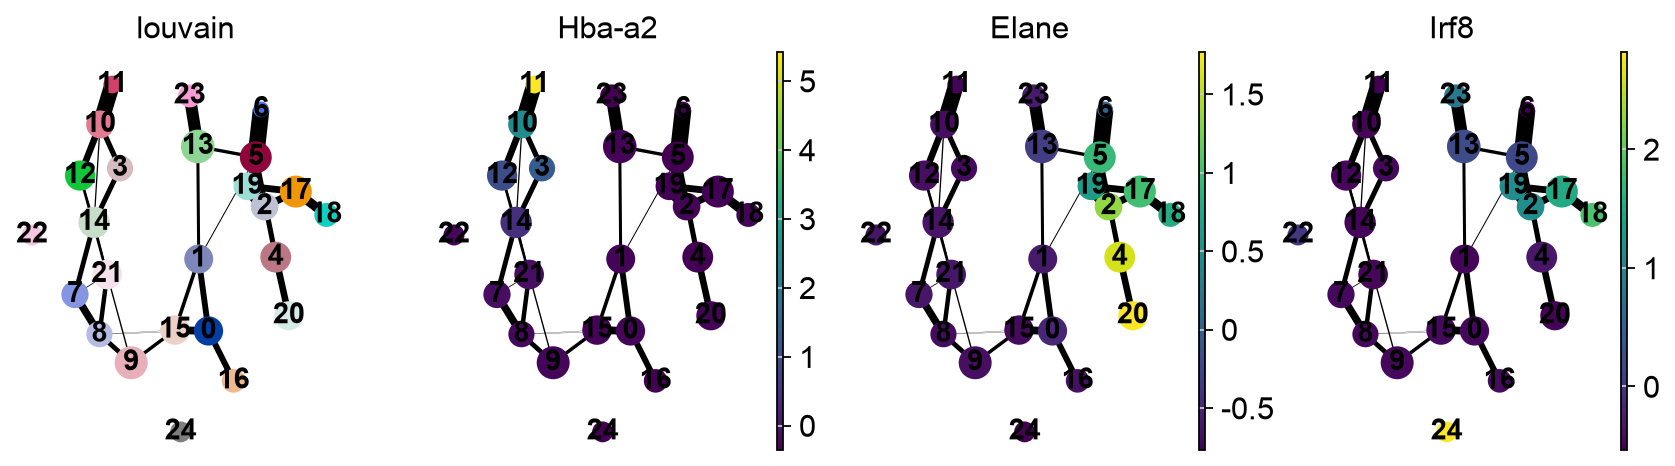

--> added 'pos', the PAGA positions (adata.uns['paga'])


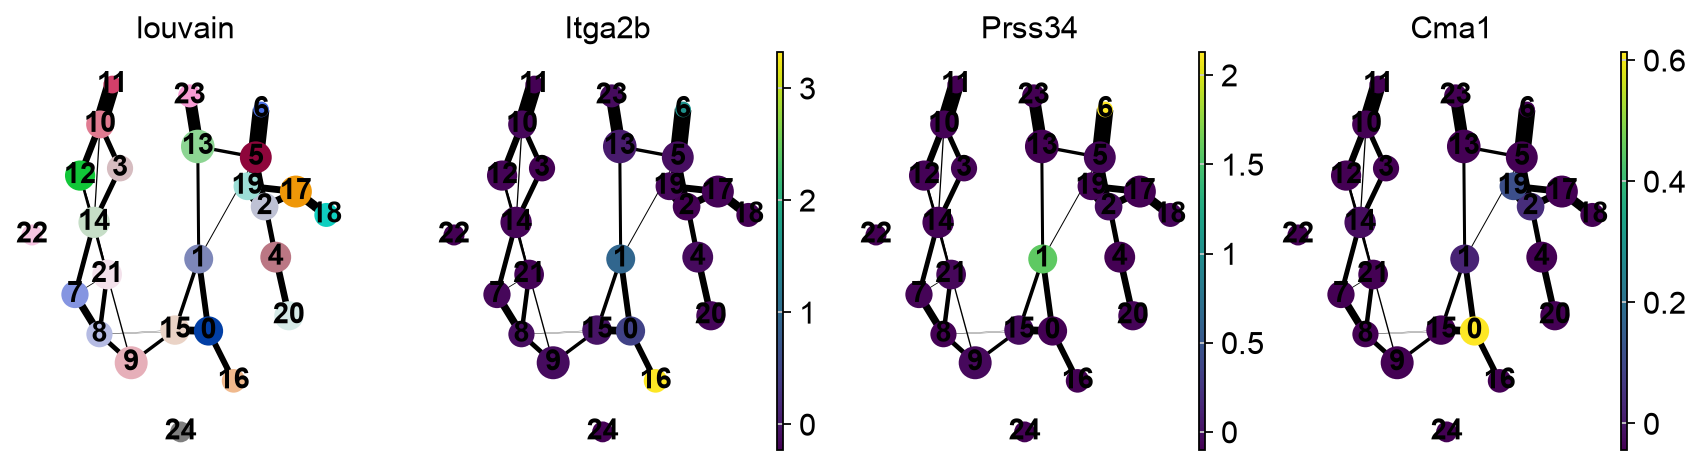

In [ ]:
sc.pl.paga(adata, color=["louvain", "Hba-a2", "Elane", "Irf8"])
sc.pl.paga(adata, color=["louvain", "Itga2b", "Prss34", "Cma1"])
# each node is clusters and the edges are the connectivity between clusters, which is calculated based on the number of edges between cells in different clusters.
# edge thickness shows how strongly connected two clusters are 
# high expression (yellow colour) shows which cluster has that gene expression most 

In [23]:
# naming the clusters 
adata.obs["louvain"].cat.categories # list the cluster labels 0 to 24
adata.obs["louvain_anno"] = adata.obs["louvain"].cat.rename_categories(
    {
        "0": "0/Stem",
        "6": "6/Baso",
        "11": "11/Ery",
        "16": "16/Mk",
        "20": "20/Neu",
        "24": "24/Mo",
    }
)

running PAGA
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:00)
--> added 'pos', the PAGA positions (adata.uns['paga'])


<Axes: >

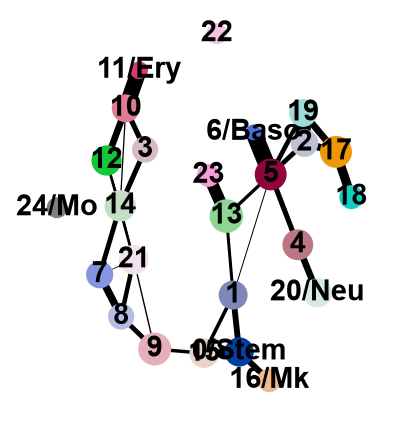

In [24]:
sc.tl.paga(adata, groups="louvain_anno")
sc.pl.paga(adata, threshold=0.03, show=False)

drawing single-cell graph using layout 'fa'
    finished: added
    'X_draw_graph_fa', graph_drawing coordinates (adata.obsm) (0:00:13)


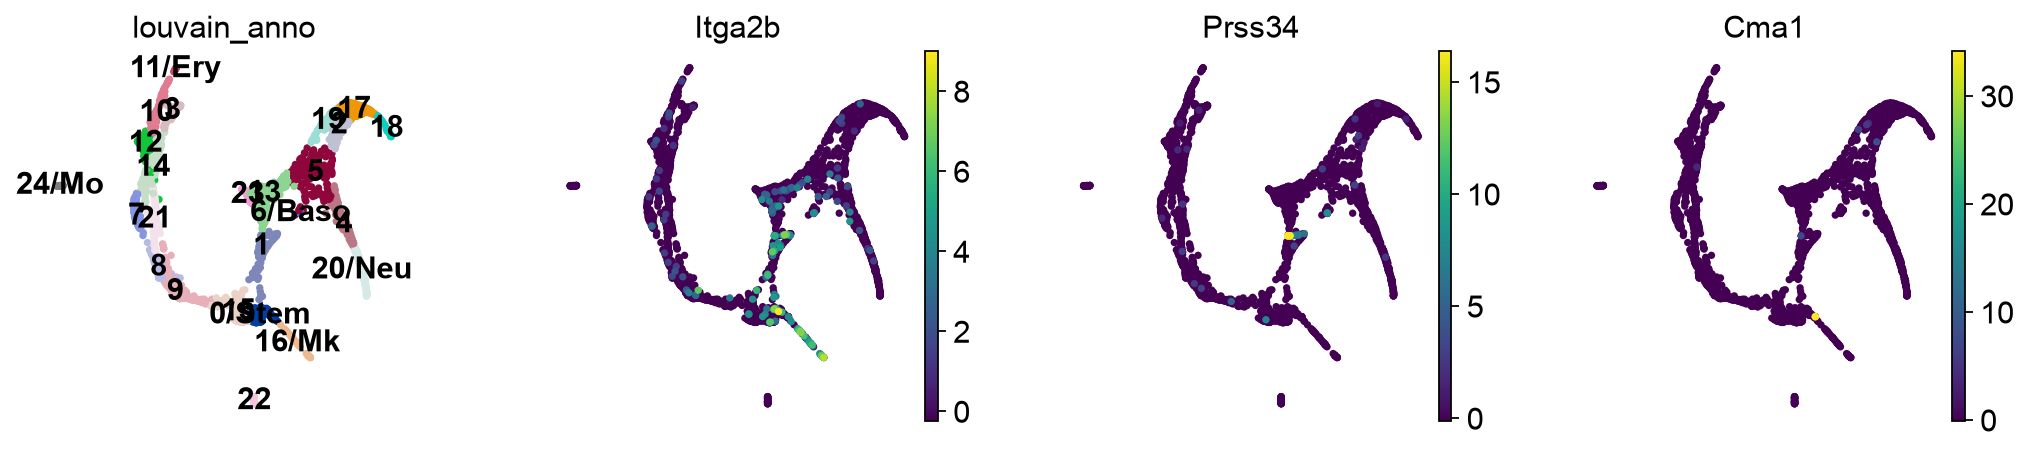

In [ ]:
# recomputing the embedding using the PAGA initialization
# starting 2,730 cells in random positions cause tangled graph and make the plot messy
# so we use PAGA to initialize the positions of the cells in the graph layout, 
# which can help to reduce the number of iterations needed to converge to a stable layout 
# and improve the overall quality of the visualization.
sc.tl.draw_graph(adata, init_pos="paga")
sc.pl.draw_graph(adata, color=["louvain_anno", "Itga2b", "Prss34", "Cma1"], legend_loc="on data")

--> added 'pos', the PAGA positions (adata.uns['paga'])


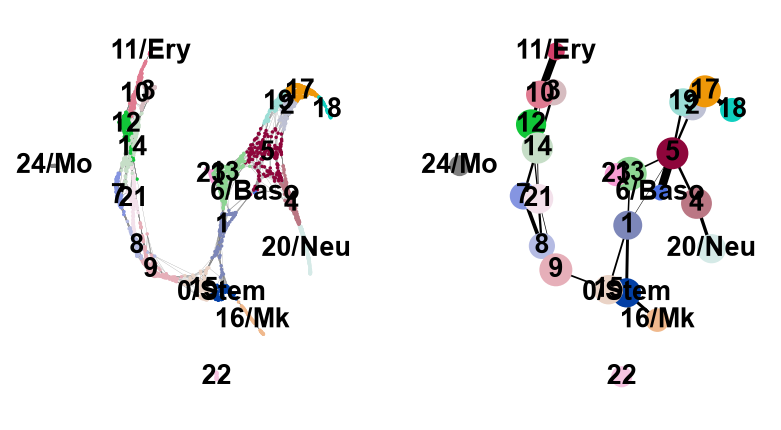

[<Axes: xlabel='FA1', ylabel='FA2'>, <Axes: >]

In [ ]:
# comparing plot
# left plot is single-cell layout, with each dot represenitng a single cell 
# right plot is PAGA graph, with each node representing a cluster of cells and 
# the edges representing the connectivity between clusters.
sc.pl.paga_compare(adata, threshold=0.03, title="", right_margin=0.2, size=10,
                   edge_width_scale=0.5, legend_fontsize=12, fontsize=12,
                   frameon=False, edges=True)

In [ ]:
# root cell and pseudotime
# PAGA graph shows the connection but not which cluster for start or end
# we set one cell from stem cluster as the root cell, 
# and then compute the pseudotime for each cell based on its distance from the root cell in the graph.
adata.uns["iroot"] = np.flatnonzero(adata.obs["louvain_anno"] == "0/Stem")[0]
sc.tl.dpt(adata)

computing Diffusion Pseudotime using n_dcs=10
    finished: added
    'dpt_pseudotime', the pseudotime (adata.obs) (0:00:00)


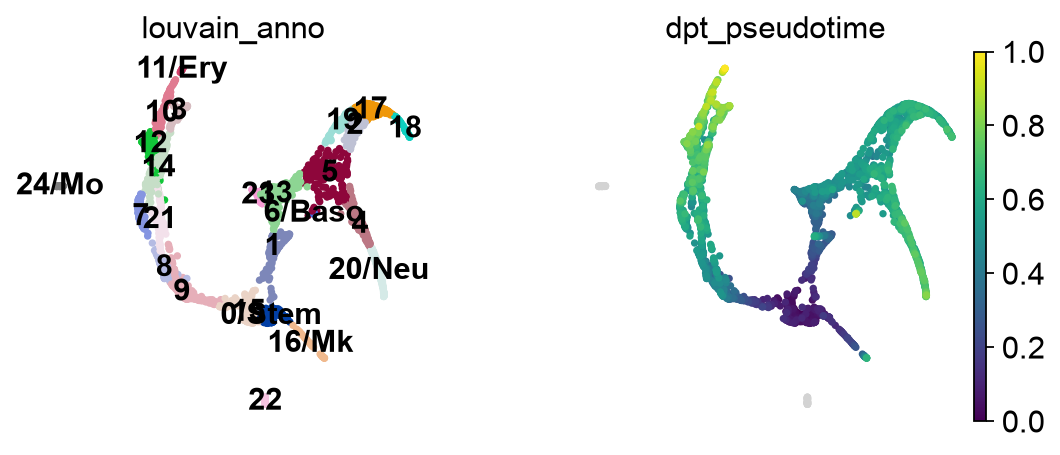

In [ ]:
# genes and raw data
gene_names = [*["Gata2", "Gata1", "Klf1", "Epor", "Hba-a2"], # erythroid
              *["Elane", "Cebpe", "Gfi1"], # neutrophil
              *["Irf8", "Csf1r", "Ctsg"]] # monocyte
adata_raw = sc.datasets.paul15()
sc.pp.log1p(adata_raw) # adata kept only 1,000 variable so reloads all 3,451 genes and preprocess them 
sc.pp.scale(adata_raw)
adata.raw = adata_raw
sc.pl.draw_graph(adata, color=["louvain_anno", "dpt_pseudotime"], legend_loc="on data")

In [29]:
paths = [
    ("erythrocytes", [0, 15, 9, 8, 7, 14, 12, 10, 11]),
    ("neutrophils", [0, 1, 19, 2, 4, 20]),
    ("monocytes", [0, 1, 19, 17, 18]),
]
adata.obs["distance"] = adata.obs["dpt_pseudotime"]
adata.obs["clusters"] = adata.obs["louvain_anno"]
adata.uns["clusters_colors"] = adata.uns["louvain_anno_colors"]

In [30]:
import os
os.makedirs("write", exist_ok=True)
os.makedirs("figures", exist_ok=True)

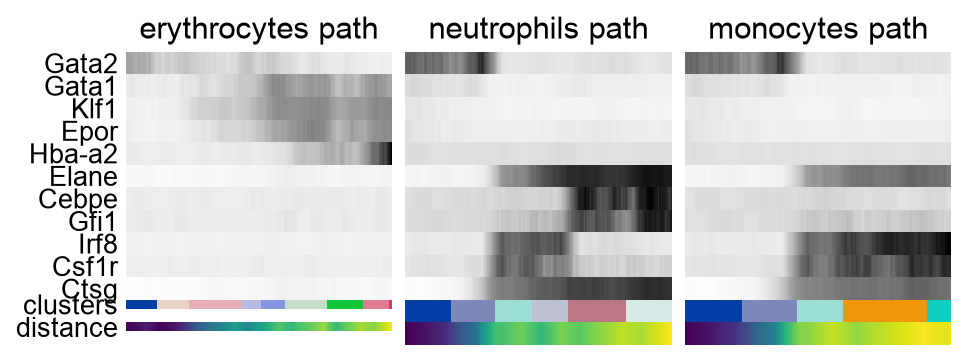

In [ ]:
_, axs = plt.subplots(ncols=3, figsize=(6, 2.5), gridspec_kw={"wspace": 0.05, "left": 0.12})
plt.subplots_adjust(left=0.05, right=0.98, top=0.82, bottom=0.2)
for ipath, (descr, path) in enumerate(paths):
    data = sc.pl.paga_path(
        adata,
        path,
        gene_names,
        show_node_names=False,
        ax=axs[ipath],
        ytick_fontsize=12,
        left_margin=0.15,
        n_avg=50,
        annotations=["distance"],
        show_yticks=ipath == 0,
        show_colorbar=False,
        color_map="Greys",
        groups_key="clusters",
        color_maps_annotations={"distance": "viridis"},
        title=f"{descr} path",
        return_data=True,
        show=False,
    )
    data.to_csv(f"./write/paga_path_{descr}.csv")
plt.savefig("./figures/paga_path_paul15.pdf")
plt.show()

# columns left (stem) to the right (differentiated) in the plot, which is consistent with the pseudotime ordering of the cells.
# darker means higher expression, and lighter means lower expression.

The erythroid and neutrophil paths show the expected order of marker genes. The monocyte path is less clean because the monocyte cluster (24) was disconnected from the graph, so the path ends at a mixed progenitor cluster (17/18), which still expresses neutrophil genes.